# Netflix Titles: Exploratory Data Analysis

An exploratory analysis of **8,807 titles** (movies and TV shows) available on Netflix, using the public `netflix_titles.csv` listing.

## Questions

1. How has the catalogue grown, and how has the movie / TV mix changed?
2. When are titles added, and how fresh are they at the time?
3. Where does the content come from, and is the mix changing?
4. Which genres dominate, and how do they differ by country?
5. Who is the content rated for?
6. How long are movies and shows?
7. Which directors and actors recur most?
8. What do the descriptions talk about?

Tools: Python, pandas, NumPy, matplotlib, seaborn, SciPy, scikit-learn (stop-word list only).

> **Scope note:** this file lists titles and when they were *added*. It has no viewing data, so every statement below is about **catalogue composition**, not popularity or viewership.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sys.path.insert(0, "../src")
import clean_netflix as cn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

IMAGES = Path("../images")
RED, DARK, GREY = "#E50914", "#221f1f", "#b3b3b3"
TYPE_COLORS = {"Movie": RED, "TV Show": DARK}

def save(name):
    plt.savefig(IMAGES / name, dpi=150, bbox_inches="tight")

## 0. Data preparation

### Load and inspect

In [2]:
raw = pd.read_csv("../data/raw/netflix_titles.csv")
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns; show_id unique: {raw['show_id'].is_unique}; "
      f"duplicate title+type+year: {raw.duplicated(['title', 'type', 'release_year']).sum()}")
raw.head(3).T

8,807 rows x 12 columns; show_id unique: True; duplicate title+type+year: 0

,0,1,2
show_id,s1,s2,s3
type,Movie,TV Show,TV Show
title,Dick Johnson Is Dead,Blood & Water,Ganglands
director,Kirsten Johnson,NaN,Julien Leclercq
cast,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...","Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi..."
country,United States,South Africa,NaN
date_added,"September 25, 2021","September 24, 2021","September 24, 2021"
release_year,2020,2021,2021
rating,PG-13,TV-MA,TV-MA
duration,90 min,2 Seasons,1 Season


In [3]:
pd.DataFrame({"dtype": raw.dtypes.astype(str),
              "missing": raw.isna().sum(),
              "missing_%": (raw.isna().mean() * 100).round(1)})

,dtype,missing,missing_%
show_id,str,0,0.0
type,str,0,0.0
title,str,0,0.0
director,str,2634,29.9
cast,str,825,9.4
country,str,831,9.4
date_added,str,10,0.1
release_year,int64,0,0.0
rating,str,4,0.0
duration,str,3,0.0


### Issues found

* **Three Louis C.K. specials have their runtime in the `rating` column** (`'74 min'`) and a blank `duration`.
* `date_added` is text (`'September 25, 2021'`).
* `duration` mixes minutes (movies) and seasons (TV) in one string column.
* `country`, `listed_in`, `director` and `cast` hold several comma-separated values per cell, and some country strings end with a stray comma.
* `NR` and `UR` both mean "not rated".
* Genuine gaps: `director` (30%), `country` (9%), `cast` (9%), plus a few missing dates and ratings.

In [4]:
print(raw.loc[raw["rating"].str.contains("min", na=False), ["title", "rating", "duration"]])
print()
print("Country strings ending in a comma:", raw["country"].str.contains(r",\s*$", na=False).sum())

                                     title  rating duration
5541                       Louis C.K. 2017  74 min      NaN
5794                 Louis C.K.: Hilarious  84 min      NaN
5813  Louis C.K.: Live at the Comedy Store  66 min      NaN

Country strings ending in a comma: 5

### Clean

The cleaning logic lives in [`src/clean_netflix.py`](../src/clean_netflix.py). It is deliberately conservative: it fixes what is demonstrably wrong, keeps real gaps as missing, and adds analysis columns (parsed dates, numeric runtime / season count, primary country and genre, rating groups).

In [5]:
df = cn.clean(raw)
df.to_csv("../data/processed/netflix_titles_clean.csv", index=False)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df[["title", "type", "date_added", "added_year", "release_to_add_years", "rating", "rating_group",
    "duration_min", "n_seasons", "primary_country", "primary_genre"]].head(5)

8,807 rows x 23 columns

,title,type,date_added,added_year,release_to_add_years,rating,rating_group,duration_min,n_seasons,primary_country,primary_genre
0,Dick Johnson Is Dead,Movie,2021-09-25,2021,1,PG-13,Teens,90,<NA>,United States,Documentaries
1,Blood & Water,TV Show,2021-09-24,2021,0,TV-MA,Adults,<NA>,2,South Africa,International TV Shows
2,Ganglands,TV Show,2021-09-24,2021,0,TV-MA,Adults,<NA>,1,NaN,Crime TV Shows
3,Jailbirds New Orleans,TV Show,2021-09-24,2021,0,TV-MA,Adults,<NA>,1,NaN,Docuseries
4,Kota Factory,TV Show,2021-09-24,2021,0,TV-MA,Adults,<NA>,2,India,International TV Shows


In [6]:
# Missing values by content type: director is missing mostly for TV shows
(df.groupby("type")[["director", "cast", "country", "date_added", "rating"]]
   .apply(lambda g: g.isna().mean() * 100).round(1))

,director,cast,country,date_added,rating
type,,,,,
Movie,3.1,7.7,7.2,0.0,0.1
TV Show,91.4,13.1,14.6,0.4,0.1


In [7]:
# Sanity checks on the cleaned data
assert df["show_id"].is_unique
assert df.loc[df["type"] == "Movie", "duration_min"].notna().all()
assert df.loc[df["type"] == "TV Show", "n_seasons"].notna().all()
assert not df["country"].dropna().str.contains(r",\s*$").any()
print("Movies without a runtime:", df.loc[df["type"] == "Movie", "duration_min"].isna().sum())
print("Titles added before their release year:", (df["release_to_add_years"] < 0).sum(), "(kept: genuine pre-release listings)")
print("Date range added:", df["date_added"].min().date(), "->", df["date_added"].max().date())

Movies without a runtime: 0
Titles added before their release year: 14 (kept: genuine pre-release listings)
Date range added: 2008-01-01 -> 2021-09-25

## 1. Catalogue growth and the movie / TV mix

In [8]:
type_share = df["type"].value_counts(normalize=True).mul(100).round(1)
print(type_share.to_string())

by_year = (df.dropna(subset=["added_year"]).groupby(["added_year", "type"]).size()
             .unstack(fill_value=0))
by_year = by_year[by_year.index >= 2014]
by_year["total"] = by_year.sum(axis=1)
by_year["tv_share_%"] = (by_year["TV Show"] / by_year["total"] * 100).round(1)
by_year

type
Movie      69.6
TV Show    30.4

type,Movie,TV Show,total,tv_share_%
added_year,,,,
2014,19,5,24,20.8
2015,56,26,82,31.7
2016,253,176,429,41.0
2017,839,349,1188,29.4
2018,1237,412,1649,25.0
2019,1424,592,2016,29.4
2020,1284,595,1879,31.7
2021,993,505,1498,33.7


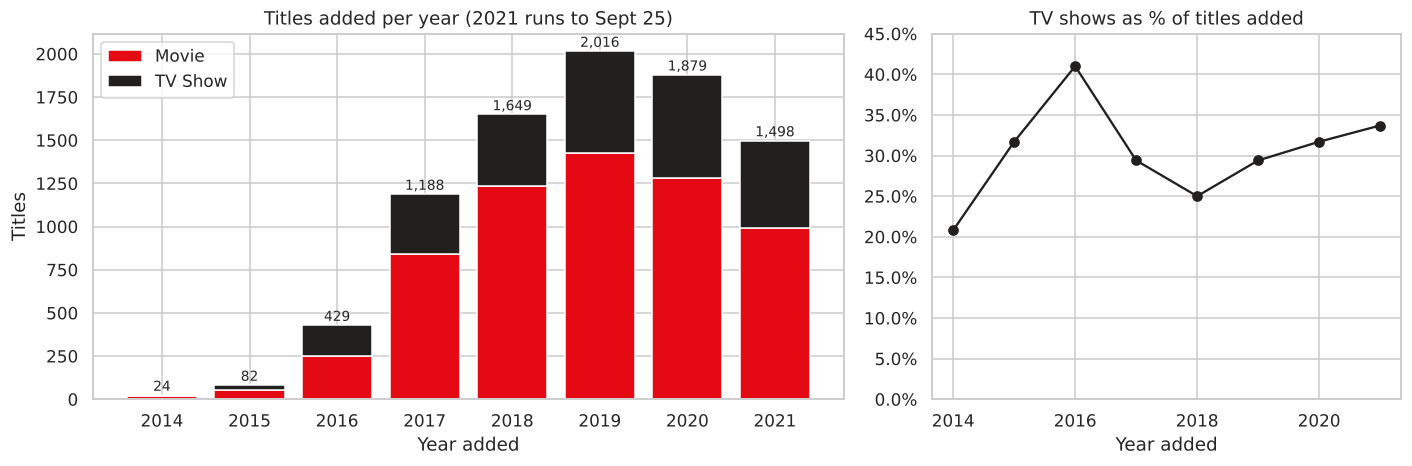

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
yrs = by_year.index.astype(int)
axes[0].bar(yrs, by_year["Movie"], color=RED, label="Movie")
axes[0].bar(yrs, by_year["TV Show"], bottom=by_year["Movie"], color=DARK, label="TV Show")
for x, t in zip(yrs, by_year["total"]):
    axes[0].text(x, t + 25, f"{t:,}", ha="center", fontsize=9)
axes[0].set_title("Titles added per year (2021 runs to Sept 25)")
axes[0].set_xlabel("Year added"); axes[0].set_ylabel("Titles"); axes[0].legend()
axes[0].set_xticks(yrs)

axes[1].plot(yrs, by_year["tv_share_%"], color=DARK, marker="o")
axes[1].set_title("TV shows as % of titles added")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_ylim(0, 45); axes[1].set_xlabel("Year added")
axes[1].set_xticks(yrs[::2])
plt.tight_layout(); save("01_catalogue_growth.png"); plt.show()

**Takeaways**

* The catalogue is **69.6% movies and 30.4% TV shows**.
* Additions rose from 429 titles in 2016 to a peak of **2,016 in 2019**, then eased to 1,879 in 2020 (about 7% lower). 2021 had 1,498 titles by 25 September.
* The TV share of new additions has moved in a band: 41% in 2016 (a small base), a low of 25% in 2018, and 32-34% in 2020-2021.
* Only 138 titles in the file were added before 2016. See the limitations: this is a 2021 snapshot, so earlier years are undercounted.

## 2. When titles are added, and how fresh they are

Median years from release to Netflix, by year added:
added_year
2015    0
2016    1
2017    1
2018    1
2019    1
2020    1
2021    1

Share of all titles released 2015 or later: 70.6%
Median release year: 2017

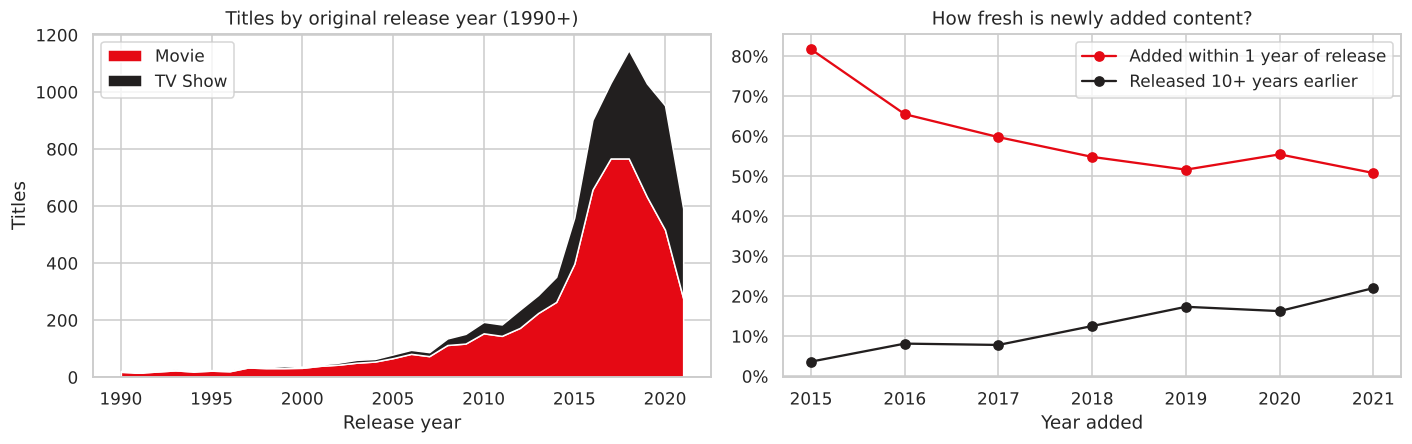

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

rel = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)
rel = rel[rel.index >= 1990]
axes[0].stackplot(rel.index, rel["Movie"], rel["TV Show"], colors=[RED, DARK], labels=["Movie", "TV Show"])
axes[0].set_title("Titles by original release year (1990+)")
axes[0].set_xlabel("Release year"); axes[0].set_ylabel("Titles"); axes[0].legend(loc="upper left")

lag = df.dropna(subset=["added_year"]).copy()
lag = lag[lag["added_year"].between(2015, 2021)]
fresh = lag.groupby("added_year")["release_to_add_years"].apply(lambda s: (s <= 1).mean() * 100)
old = lag.groupby("added_year")["release_to_add_years"].apply(lambda s: (s >= 10).mean() * 100)
axes[1].plot(fresh.index.astype(int), fresh.values, color=RED, marker="o", label="Added within 1 year of release")
axes[1].plot(old.index.astype(int), old.values, color=DARK, marker="o", label="Released 10+ years earlier")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_title("How fresh is newly added content?")
axes[1].set_xlabel("Year added"); axes[1].legend()
plt.tight_layout(); save("02_release_year_and_freshness.png"); plt.show()

print("Median years from release to Netflix, by year added:")
print(lag.groupby("added_year")["release_to_add_years"].median().astype(int).to_string())
print(f"\nShare of all titles released 2015 or later: {(df['release_year'] >= 2015).mean():.1%}")
print(f"Median release year: {int(df['release_year'].median())}")

**Takeaways**

* The catalogue is recent: **70.6% of titles were released in 2015 or later** and the median release year is 2017.
* The typical title reaches Netflix about a year after release (median gap of 1 year in every year since 2016).
* Freshness is slowly falling. Titles added within a year of release dropped from 65.5% of additions in 2016 to roughly 51-56% in 2019-2021, while titles that were **10+ years old rose from 8.2% (2016) to 22.0% (2021)**. More of the catalogue is now back-catalogue.

added_month
Dec    10.9
Oct    10.2
Nov     9.7
Mar     8.7
Lowest: Feb 6.2%

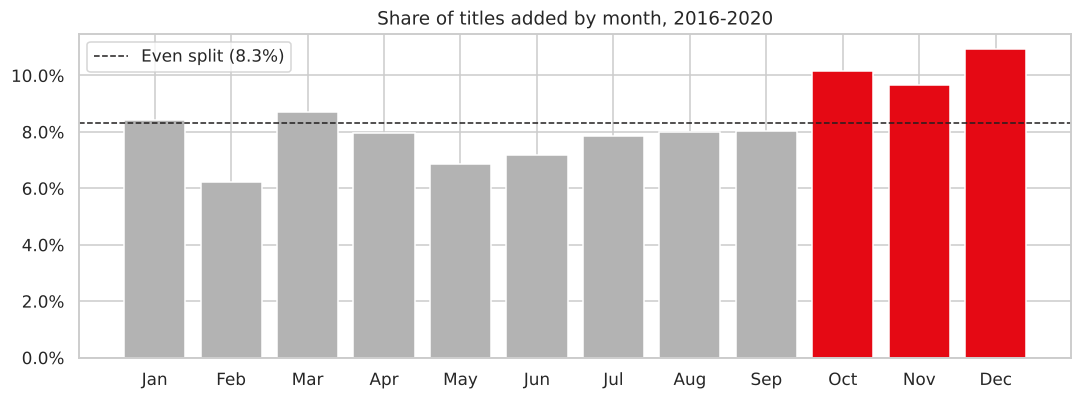

In [11]:
# Seasonality, using only complete calendar years 2016-2020
full = df[df["added_year"].between(2016, 2020)]
month_counts = full.groupby("added_month").size()
month_share = month_counts / month_counts.sum() * 100
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
top3 = month_share.nlargest(3).index

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(months, month_share.values, color=[RED if m in top3 else GREY for m in month_share.index])
ax.axhline(100 / 12, color=DARK, ls="--", lw=1, label="Even split (8.3%)")
ax.set_title("Share of titles added by month, 2016-2020")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend()
plt.tight_layout(); save("03_seasonality.png"); plt.show()
print(month_share.round(1).rename(dict(enumerate(months, 1))).sort_values(ascending=False).head(4).to_string())
print("Lowest:", months[month_share.idxmin() - 1], f"{month_share.min():.1f}%")

**Takeaways**

* Additions are seasonal: **December (10.9%), October (10.2%) and November (9.7%)** are the busiest months, so Q4 accounts for 30.8% of a year's additions against 25% if spread evenly.
* **February is the quietest month at 6.2%.**
* Based on 2016-2020 only; those are the five complete calendar years in the data.

## 3. Where the content comes from

A title can list several countries (co-productions), so these counts are **appearances**, not exclusive titles.

Titles with a country listed: 7,976 of 8,807 (90.6%)
Titles listing 2+ countries: 1,315 (14.9%)
Distinct countries: 122
Movie vs TV mix inside each country's catalogue (% of its titles):

type,Movie,TV Show
c,,
United States,74.6,25.4
India,92.0,8.0
United Kingdom,66.3,33.7
Canada,71.7,28.3
France,77.1,22.9
Japan,37.4,62.6
Spain,73.7,26.3
South Korea,26.4,73.6


,United States,India,United Kingdom,South Korea,Japan
2016,49.5,3.2,13.2,2.7,7.1
2017,41.1,14.4,11.9,3.8,3.3
2018,39.2,22.8,9.6,2.2,2.9
2019,46.1,11.7,10.3,3.2,4.0
2020,46.8,11.2,8.2,3.2,4.5
2021,55.0,9.2,10.5,2.5,4.6


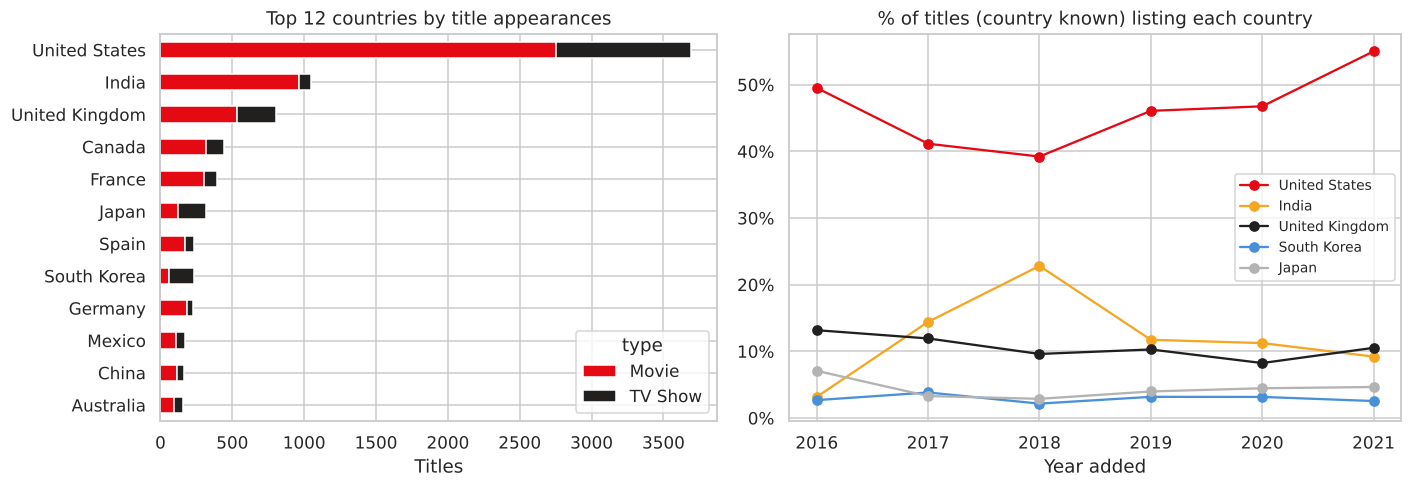

In [12]:
ctry = df.dropna(subset=["country"]).assign(c=lambda d: d["country"].str.split(", ")).explode("c")
known = df["country"].notna().sum()
print(f"Titles with a country listed: {known:,} of {len(df):,} ({known / len(df):.1%})")
print(f"Titles listing 2+ countries: {(df['n_countries'] >= 2).sum():,} ({(df['n_countries'] >= 2).mean():.1%})")
print(f"Distinct countries: {ctry['c'].nunique()}")

top_c = ctry["c"].value_counts().head(12)
by_c = ctry[ctry["c"].isin(top_c.index)].groupby(["c", "type"]).size().unstack(fill_value=0).loc[top_c.index[::-1]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
by_c.plot.barh(stacked=True, color=[RED, DARK], ax=axes[0])
axes[0].set_title("Top 12 countries by title appearances"); axes[0].set_ylabel(""); axes[0].set_xlabel("Titles")

focus = ["United States", "India", "United Kingdom", "South Korea", "Japan"]
yrs = range(2016, 2022)
share = pd.DataFrame({
    c: [ctry[(ctry["added_year"] == y) & (ctry["c"] == c)].shape[0]
        / df[(df["added_year"] == y) & df["country"].notna()].shape[0] * 100 for y in yrs]
    for c in focus}, index=list(yrs))
palette = [RED, "#f5a623", DARK, "#4a90d9", GREY]
for c, col in zip(focus, palette):
    axes[1].plot(share.index, share[c], marker="o", label=c, color=col)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_title("% of titles (country known) listing each country")
axes[1].set_xlabel("Year added"); axes[1].legend(fontsize=9)
plt.tight_layout(); save("04_countries.png"); plt.show()
print("Movie vs TV mix inside each country's catalogue (% of its titles):")
top8c = ctry["c"].value_counts().head(8).index
mix = ctry[ctry["c"].isin(top8c)].groupby(["c", "type"])["show_id"].nunique().unstack(fill_value=0)
mix = mix.div(mix.sum(axis=1), axis=0).mul(100).round(1).loc[top8c]
display(mix)
share.round(1)

**Takeaways**

* The **United States appears on 46% of titles that list a country** (3,690 titles), followed by India (1,046), the United Kingdom (806), Canada (445) and France (393). 14.9% of titles are co-productions listing 2+ countries.
* India's share of new titles peaked at **22.8% in 2018** and has fallen back to about 9% in 2021, while the US share climbed to 55% in 2021 (a partial year, and the 2016 base is small).
* Country catalogues have very different shapes: **India is 92% movies**, while **South Korea (74%) and Japan (63%) are mostly TV shows**.

## 4. Genres

Netflix uses different labels for movies and TV (`Dramas` vs `TV Dramas`), and some tags describe geography (`International Movies`, `British TV Shows`) rather than genre. I map equivalent labels to one genre and drop the geographic tags.

Titles with at least one mapped genre: 8,729 of 8,807

,count
genre,
Drama,3190
Comedy,2255
Documentary,1264
Kids & Family,1092
Action & Adventure,1027
Romance,986
Independent,756
Thriller,634
Crime,470


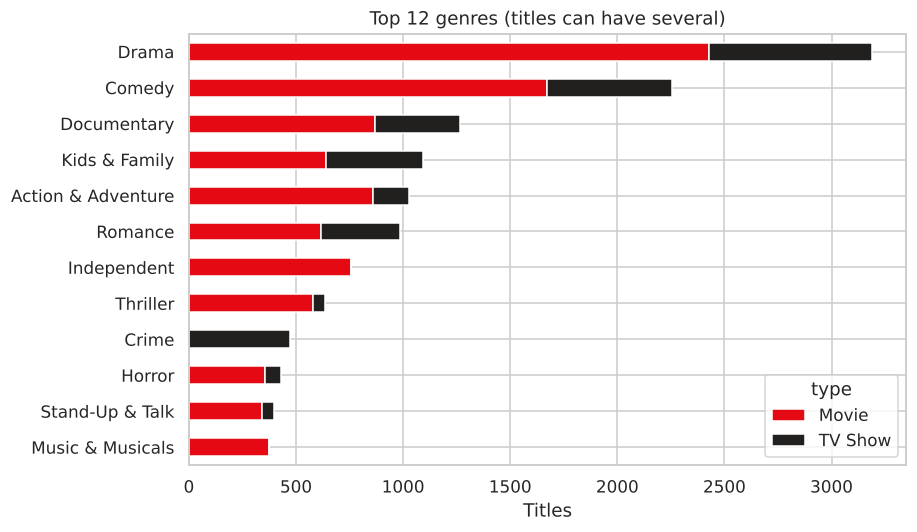

In [13]:
GENRE_MAP = {
    "Dramas": "Drama", "TV Dramas": "Drama",
    "Comedies": "Comedy", "TV Comedies": "Comedy",
    "Action & Adventure": "Action & Adventure", "TV Action & Adventure": "Action & Adventure",
    "Documentaries": "Documentary", "Docuseries": "Documentary",
    "Romantic Movies": "Romance", "Romantic TV Shows": "Romance",
    "Horror Movies": "Horror", "TV Horror": "Horror",
    "Thrillers": "Thriller", "TV Thrillers": "Thriller",
    "Crime TV Shows": "Crime",
    "Children & Family Movies": "Kids & Family", "Kids' TV": "Kids & Family",
    "Sci-Fi & Fantasy": "Sci-Fi & Fantasy", "TV Sci-Fi & Fantasy": "Sci-Fi & Fantasy",
    "Stand-Up Comedy": "Stand-Up & Talk", "Stand-Up Comedy & Talk Shows": "Stand-Up & Talk",
    "Reality TV": "Reality", "Anime Series": "Anime", "Anime Features": "Anime",
    "Music & Musicals": "Music & Musicals", "Independent Movies": "Independent",
    "TV Mysteries": "Mystery", "Sports Movies": "Sports", "Teen TV Shows": "Teen",
    "Classic Movies": "Classic & Cult", "Cult Movies": "Classic & Cult", "Classic & Cult TV": "Classic & Cult",
    "LGBTQ Movies": "LGBTQ", "Science & Nature TV": "Science & Nature", "Faith & Spirituality": "Faith & Spirituality",
}
gen = (df.assign(g=df["listed_in"].str.split(", ")).explode("g")
         .assign(genre=lambda d: d["g"].map(GENRE_MAP)).dropna(subset=["genre"])
         .drop_duplicates(["show_id", "genre"]))
print(f"Titles with at least one mapped genre: {gen['show_id'].nunique():,} of {len(df):,}")

top_g = gen["genre"].value_counts().head(12)
by_g = gen[gen["genre"].isin(top_g.index)].groupby(["genre", "type"]).size().unstack(fill_value=0).loc[top_g.index[::-1]]
fig, ax = plt.subplots(figsize=(8.5, 5))
by_g.plot.barh(stacked=True, color=[RED, DARK], ax=ax)
ax.set_title("Top 12 genres (titles can have several)"); ax.set_ylabel(""); ax.set_xlabel("Titles")
plt.tight_layout(); save("05_genres.png"); plt.show()
top_g

Genre each country over-indexes on most (vs average of these 8 countries):
c
United States            Documentary
India                          Drama
United Kingdom           Documentary
Canada                 Kids & Family
France                   Independent
Japan             Action & Adventure
Spain                          Crime
South Korea                  Romance

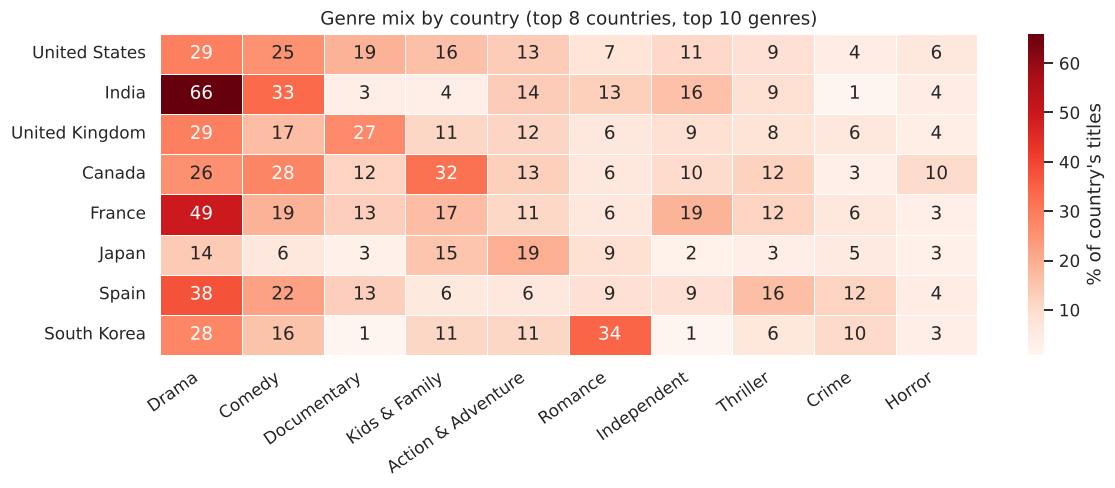

In [14]:
# What is each country's catalogue made of? (% of that country's titles in each genre)
top8 = ctry["c"].value_counts().head(8).index
cg = (ctry[ctry["c"].isin(top8)].assign(g=lambda d: d["listed_in"].str.split(", ")).explode("g")
        .assign(genre=lambda d: d["g"].map(GENRE_MAP)).dropna(subset=["genre"])
        .drop_duplicates(["show_id", "c", "genre"]))
n_titles = ctry[ctry["c"].isin(top8)].groupby("c")["show_id"].nunique()
mat = cg.groupby(["c", "genre"]).size().unstack(fill_value=0).div(n_titles, axis=0).mul(100)
mat = mat.loc[top8, top_g.index[:10]]

fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(mat, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of country's titles"}, ax=ax, linewidths=.5)
ax.set_title("Genre mix by country (top 8 countries, top 10 genres)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); save("06_genre_by_country.png"); plt.show()

# Most over-represented genre for each country, relative to the whole catalogue
overall = gen["genre"].value_counts(normalize=True)
rel_idx = mat.div(mat.mean(axis=0), axis=1)
print("Genre each country over-indexes on most (vs average of these 8 countries):")
print(rel_idx.idxmax(axis=1).to_string())

**Takeaways**

* **Drama (3,190 titles) and Comedy (2,255)** lead, followed by Documentary, Kids & Family and Action & Adventure.
* Country profiles differ: relative to the other top-8 countries, the US and UK over-index on Documentary, India on Drama, South Korea on Romance, France on Independent films, Spain on Crime and Canada on Kids & Family.

## 5. Who is it for? Ratings

Share rated TV-MA or R (adult):
type
Movie      46.7
TV Show    42.9

Chi-square test, type vs audience group: chi2=229.6, dof=4, p=1.6e-48, Cramer's V=0.16

rating_group,Kids,Older kids / family,Teens,Adults
added_year,,,,
2015,23.2,12.2,19.5,39.0
2016,15.3,12.4,24.4,41.5
2017,9.1,15.8,29.7,43.3
2018,8.1,13.2,30.6,47.3
2019,7.8,13.8,31.2,46.9
2020,12.1,12.3,29.9,45.7
2021,12.8,10.3,31.5,45.3


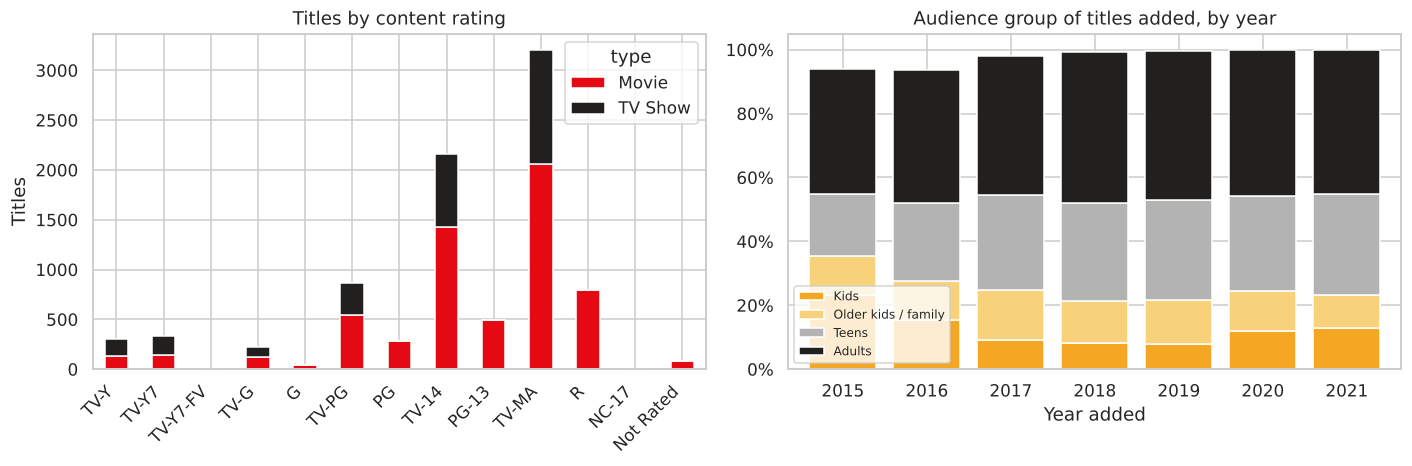

In [15]:
order = ["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G", "TV-PG", "PG", "TV-14", "PG-13", "TV-MA", "R", "NC-17", "Not Rated"]
rc = df.groupby(["rating", "type"]).size().unstack(fill_value=0).reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
rc.plot.bar(stacked=True, color=[RED, DARK], ax=axes[0])
axes[0].set_title("Titles by content rating"); axes[0].set_xlabel(""); axes[0].set_ylabel("Titles")
plt.setp(axes[0].get_xticklabels(), rotation=45, ha="right")

g = (df[df["added_year"].between(2015, 2021)].groupby(["added_year", "rating_group"], observed=True)
       .size().unstack(fill_value=0))
g = g.div(g.sum(axis=1), axis=0) * 100
g = g[["Kids", "Older kids / family", "Teens", "Adults"]]
g.index = g.index.astype(int)
g.plot.bar(stacked=True, ax=axes[1], color=["#f5a623", "#f8d27a", GREY, DARK], width=.8)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_title("Audience group of titles added, by year"); axes[1].set_xlabel("Year added"); axes[1].legend(fontsize=8, loc="lower left")
plt.setp(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout(); save("07_ratings.png"); plt.show()

print("Share rated TV-MA or R (adult):")
adult = df.groupby("type")["rating_group"].apply(lambda s: (s == "Adults").sum() / s.notna().sum() * 100).round(1)
print(adult.to_string())

# Is the type / audience link statistically meaningful?
ct = pd.crosstab(df["type"], df["rating_group"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
print(f"\nChi-square test, type vs audience group: chi2={chi2:.1f}, dof={dof}, p={p:.2g}, Cramer's V={cramers_v:.2f}")
g.round(1)

**Takeaways**

* **TV-MA is the single most common rating (3,207 titles)**, ahead of TV-14 (2,160).
* Adult-rated content (TV-MA, R, NC-17) is 46.7% of movies and 42.9% of TV shows. TV shows are not more mature than movies here; the clearest difference is that **TV has more kids' content (17.4% vs 7.2%)**.
* The type / audience link is statistically significant (chi-square p < 0.001) but modest in size (Cramer's V = 0.16).
* Over time, the adult share of additions grew from 39.0% (2015) to about 47% (2018-2019), and the kids' share fell from 23.2% (2015) to 7.8% (2019) before recovering to 12.8% in 2021.

## 6. Duration: movie runtime and TV seasons

count    6131.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0

Movies shorter than 60 min: 458 (7.5%)
TV shows with a single season: 67.0%; longest run: 17 seasons (Grey's Anatomy)

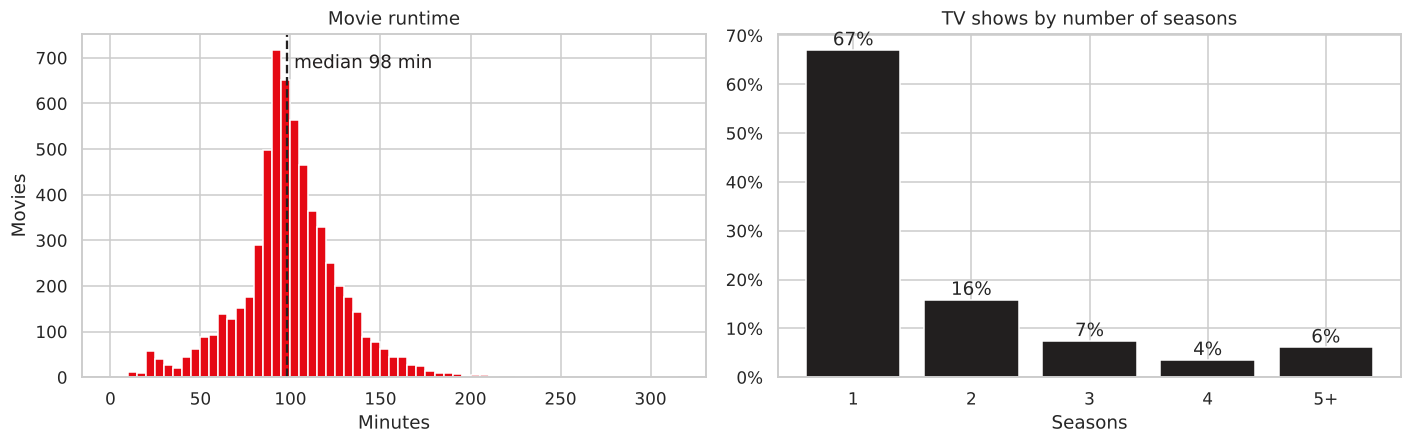

In [16]:
movies = df[df["type"] == "Movie"]
shows = df[df["type"] == "TV Show"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(movies["duration_min"].dropna().astype(float), bins=np.arange(0, 320, 5), color=RED)
med = movies["duration_min"].median()
axes[0].axvline(med, color=DARK, ls="--"); axes[0].text(med + 4, axes[0].get_ylim()[1] * .9, f"median {med:.0f} min", color=DARK)
axes[0].set_title("Movie runtime"); axes[0].set_xlabel("Minutes"); axes[0].set_ylabel("Movies")

seasons = shows["n_seasons"].astype(int).clip(upper=5).value_counts().sort_index()
seasons.index = ["1", "2", "3", "4", "5+"]
axes[1].bar(seasons.index, seasons.values / seasons.sum() * 100, color=DARK)
for i, v in enumerate(seasons.values / seasons.sum() * 100):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center")
axes[1].set_title("TV shows by number of seasons"); axes[1].set_xlabel("Seasons"); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); save("08_duration.png"); plt.show()

print(movies["duration_min"].describe().round(1).to_string())
print(f"\nMovies shorter than 60 min: {(movies['duration_min'] < 60).sum()} ({(movies['duration_min'] < 60).mean():.1%})")
print(f"TV shows with a single season: {(shows['n_seasons'] == 1).mean():.1%}; longest run: {int(shows['n_seasons'].max())} seasons "
      f"({shows.loc[shows['n_seasons'].idxmax(), 'title']})")

,count,median
genre,,
Documentary,869,86.0
Kids & Family,641,87.0
Independent,756,98.0
Comedy,1674,101.0
Music & Musicals,375,101.0
Thriller,577,103.0
Romance,616,107.0
Action & Adventure,859,108.0
Drama,2427,109.0


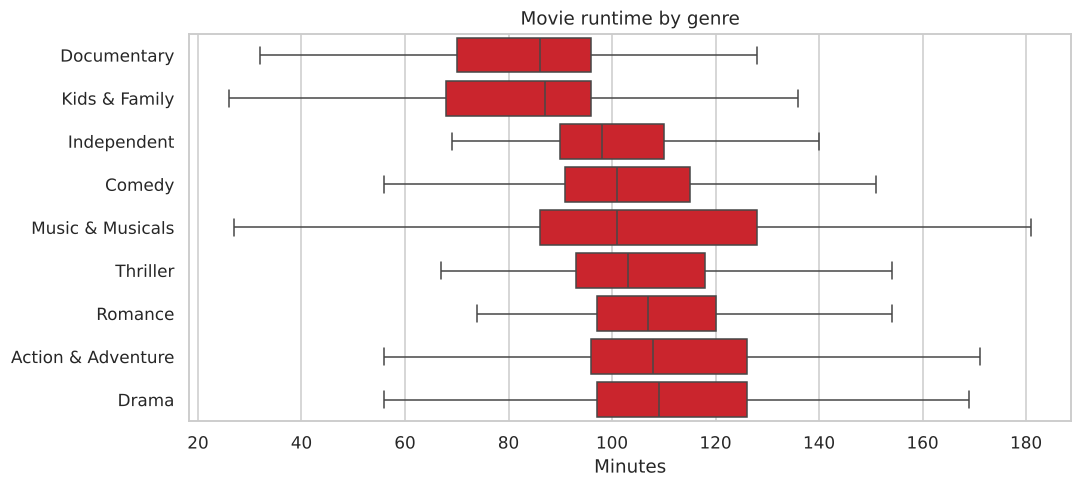

In [17]:
# Runtime by genre (movies only)
mg = gen[gen["type"] == "Movie"].dropna(subset=["duration_min"])
top_mg = mg["genre"].value_counts().head(9).index
order = mg[mg["genre"].isin(top_mg)].groupby("genre")["duration_min"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.boxplot(data=mg[mg["genre"].isin(top_mg)].assign(duration_min=lambda d: d["duration_min"].astype(float)),
            y="genre", x="duration_min", order=order, color=RED, showfliers=False, ax=ax)
ax.set_title("Movie runtime by genre"); ax.set_xlabel("Minutes"); ax.set_ylabel("")
plt.tight_layout(); save("09_runtime_by_genre.png"); plt.show()
mg[mg["genre"].isin(top_mg)].groupby("genre")["duration_min"].agg(["count", "median"]).sort_values("median")

**Takeaways**

* The **median movie runs 98 minutes** (middle half: 87-114). 7.5% of movies (458) are under an hour.
* By genre, **Documentaries (86 min) and Kids & Family (87 min) are shortest**, and Dramas the longest (109 min) among the nine biggest genres.
* **67.0% of TV shows have a single season**, about 17% reach three or more, and the longest run in the file is 17 seasons (Grey's Anatomy).

## 7. Directors and actors

Directors are missing for about 30% of titles (mostly TV shows), and cast for about 9%, so these rankings describe **listed credits only**.

Directors credited on exactly one title: 79.5% of 4,993 directors

,director,titles,top_country
0,Rajiv Chilaka,22,India
1,Jan Suter,21,Mexico
2,Raúl Campos,19,Mexico
3,Suhas Kadav,16,India
4,Marcus Raboy,16,United States
5,Jay Karas,15,United States
6,Cathy Garcia-Molina,13,Philippines
7,Youssef Chahine,12,Egypt
8,Martin Scorsese,12,United States
9,Jay Chapman,12,United States


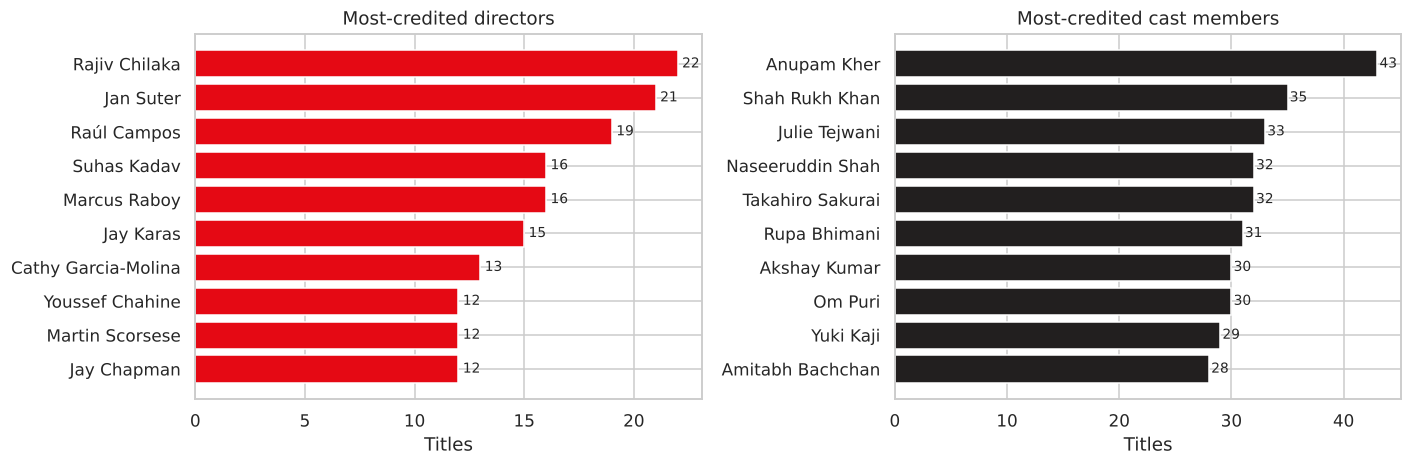

In [18]:
dirs = df.dropna(subset=["director"]).assign(p=lambda d: d["director"].str.split(", ")).explode("p")
cast = df.dropna(subset=["cast"]).assign(p=lambda d: d["cast"].str.split(", ")).explode("p")
td, tc = dirs["p"].value_counts().head(10), cast["p"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].barh(td.index[::-1], td.values[::-1], color=RED); axes[0].set_title("Most-credited directors")
axes[1].barh(tc.index[::-1], tc.values[::-1], color=DARK); axes[1].set_title("Most-credited cast members")
for ax, s in zip(axes, [td, tc]):
    ax.set_xlabel("Titles")
    for y, v in enumerate(s.values[::-1]): ax.text(v + .2, y, str(v), va="center", fontsize=9)
plt.tight_layout(); save("10_directors_actors.png"); plt.show()

print("Directors credited on exactly one title:", f"{(dirs['p'].value_counts() == 1).mean():.1%} of {dirs['p'].nunique():,} directors")
pd.DataFrame({"director": td.index, "titles": td.values, "top_country": [
    ctry_ for ctry_ in [dirs[dirs['p'] == d]['primary_country'].mode().iloc[0] for d in td.index]]})

**Takeaways**

* The most-credited directors have 12-22 titles each, and their main countries span India, Mexico, the US, the Philippines and Egypt.
* The pool is long-tailed: **79.5% of the 4,993 credited directors appear on only one title.**

## 8. What the descriptions talk about

A simple word-frequency view of the one-sentence descriptions, after removing standard English stop words and a few generic filler words.

,Movie,TV Show
0,life,series
1,young,life
2,man,world
3,family,family
4,woman,friends
5,love,young
6,documentary,love
7,world,school
8,father,high
9,friends,woman


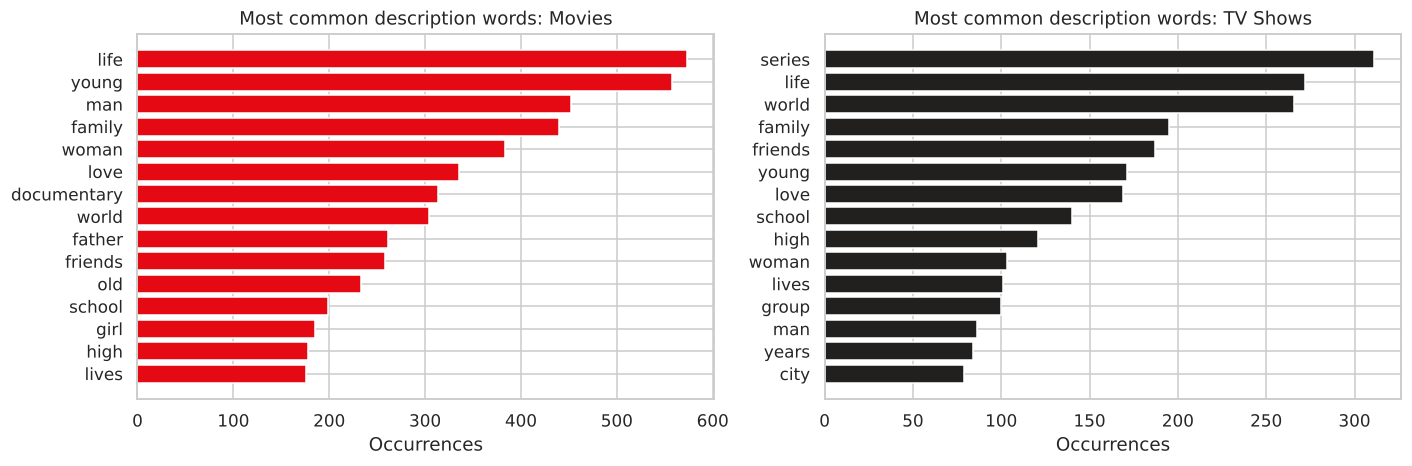

In [19]:
extra = {"new", "finds", "find", "must", "tries", "try", "becomes", "gets", "get", "takes", "take", "help", "helps",
         "make", "makes", "one", "two", "back", "home", "way", "just", "will", "can", "comes", "come", "goes", "go",
         "set", "turns", "turn", "meets", "meet", "start", "starts", "leads", "lead"}
stop = set(ENGLISH_STOP_WORDS) | extra
tokens = lambda s: [w for w in re.findall(r"[a-z]{3,}", s.lower()) if w not in stop]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
top_words = {}
for ax, (t, colr) in zip(axes, [("Movie", RED), ("TV Show", DARK)]):
    words = pd.Series([w for d in df.loc[df["type"] == t, "description"] for w in tokens(d)]).value_counts().head(15)
    top_words[t] = words
    ax.barh(words.index[::-1], words.values[::-1], color=colr)
    ax.set_title(f"Most common description words: {t}s"); ax.set_xlabel("Occurrences")
plt.tight_layout(); save("11_description_words.png"); plt.show()
pd.DataFrame({t: w.index for t, w in top_words.items()})

**Takeaways**

* Movie descriptions lean on people and relationships (*life, young, man, family, woman, love*), with *documentary* ranking among the top words.
* TV descriptions are more about ensembles and setting (*series, life, world, family, friends, school, city*).

## Summary of findings

1. **Mostly movies, mostly recent.** 69.6% of titles are movies and 70.6% were released in 2015 or later.
2. **Growth peaked in 2019** (2,016 additions) and eased in 2020; 2021 ran to September.
3. **Q4 is the busiest season for additions** (30.8% of the year in Oct-Dec) and February the quietest.
4. **The catalogue is ageing slowly:** titles 10+ years old rose from 8.2% of additions in 2016 to 22.0% in 2021.
5. **US-centred but international:** the US appears on 46% of titles with a country, with distinct national profiles (India movie-heavy, South Korea and Japan TV-heavy).
6. **Drama and Comedy dominate genres;** adult ratings make up 43-47% of both movies and TV.
7. **Movies are around 98 minutes; two-thirds of shows have only one season.**
8. **Credits are long-tailed:** about 4 in 5 directors appear on a single title.

## Limitations

* The file has **no viewing, popularity or revenue data**; everything describes catalogue composition.
* `date_added` stops at 25 Sep 2021, so 2021 is a partial year and is compared with caution.
* Countries, genres, directors and cast are multi-valued, so counts are *appearances*; shares can sum to more than 100%.
* About 30% of directors, 9% of countries and 9% of cast are missing. Missing is not random (director is blank for most TV shows), so rankings reflect listed credits only.
* The file is a **snapshot of the catalogue as of 2021**. Titles that were added and later removed are absent, so the early years look smaller than the real catalogue was and the growth curve is probably overstated.
* Genre mapping is a judgment call: merging movie and TV labels and dropping geographic tags changes counts slightly.